# Chapitre 5 - Cours 1 : réplication à leader unique

Répliquer, c'est garder une copie des mêmes données sur plusieurs machines reliées par
un réseau. Tant que les données ne changent pas, c'est trivial : on copie une fois. Toute
la difficulté vient des **modifications**. Ce premier cours étudie la famille la plus
répandue, la réplication à **leader unique** (leader-based, primary-backup,
active/passive) : un nœud reçoit toutes les écritures et les transmet aux autres. Il
couvre l'introduction du chapitre et la section *Leaders and Followers* jusqu'à
*Handling Node Outages* inclus.

**Plan.**

1. Trois raisons de répliquer, et le schéma leader-suiveurs.
2. Synchrone, asynchrone, semi-synchrone : latence et disponibilité des écritures.
3. Ajouter un suiveur sans arrêter le leader.
4. Panne d'un suiveur : le rattrapage.
5. Panne du leader : le basculement et les écritures perdues.
6. Split brain, fencing et clés réutilisées.

Les simulations reposent sur le simulateur à événements `ddia.sim` et sur le module
[`ddia/replication.py`](../../ddia/replication.py) (classes `ReplNode`, `Controller`,
`WriterClient`, fonction `failover_scenario`).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Trois raisons de répliquer (introduction du chapitre)

On réplique pour trois raisons, qui reviendront tout au long du chapitre :

- **latence** : garder les données près des utilisateurs (une réplique par continent) ;
- **disponibilité et durabilité** : continuer à servir, et ne rien perdre, quand une
  machine (ou tout un centre de données) tombe ;
- **débit de lecture** : multiplier les machines qui répondent aux lectures.

Ce chapitre suppose que chaque machine peut contenir **toute** la base ; découper une
base trop grosse est l'objet du chapitre 6. Il étudie trois familles
d'algorithmes, que presque toutes les bases distribuées utilisent : leader unique,
multi-leader et sans leader.

**Le schéma leader-suiveurs.** Une réplique est désignée **leader** (ou primaire) :
toutes les écritures des clients passent par elle. Elle les applique à son stockage
local puis les envoie aux autres répliques, les **suiveurs** (followers, réplicas de
lecture, secondaires), sous la forme d'un **journal de réplication** (flux de
changements). Chaque suiveur applique les écritures **dans le même ordre** que le leader.
Les lectures peuvent aller au leader ou à n'importe quel suiveur. C'est le fonctionnement
par défaut de PostgreSQL, MySQL, Oracle Data Guard, SQL Server, MongoDB, et aussi de
Kafka.

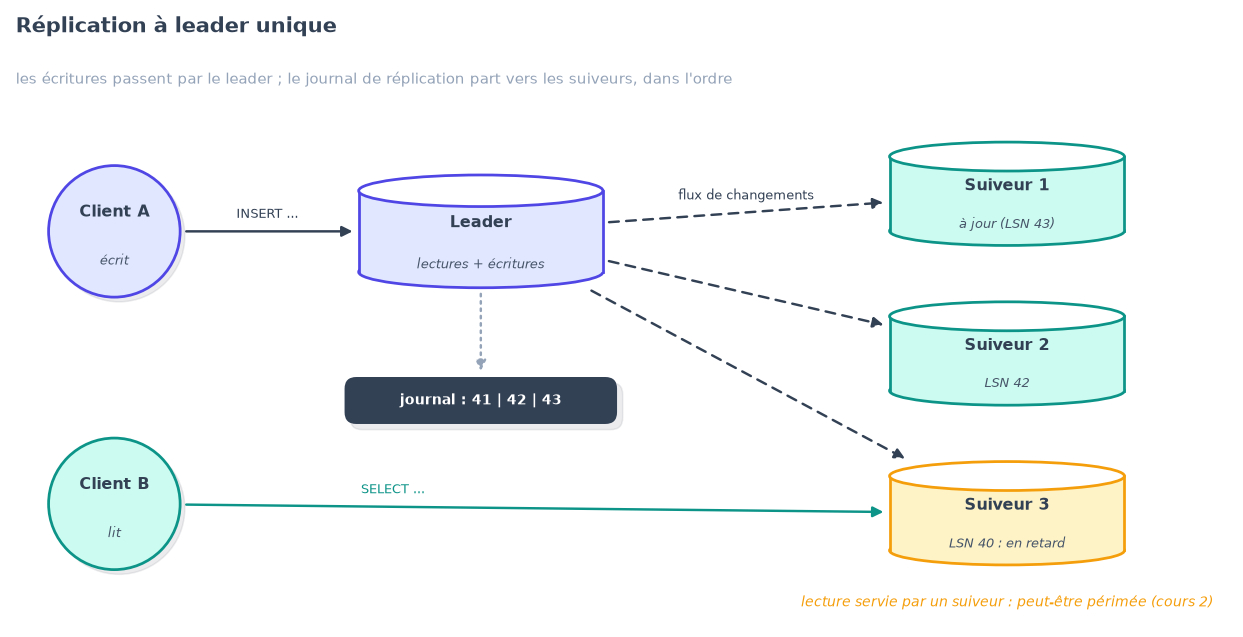

In [2]:
d = Diagram(13, 5.6, title="Réplication à leader unique",
            subtitle="les écritures passent par le leader ; le journal de réplication part vers les suiveurs, dans l'ordre")
d.box("w", 1.1, 4.2, "Client A", sub="écrit", kind="user", w=1.4, color=INDIGO)
d.box("r1", 1.1, 1.3, "Client B", sub="lit", kind="user", w=1.4, color=TEAL)
d.box("L", 5.0, 4.2, "Leader", sub="lectures + écritures", color=INDIGO, kind="db", w=2.6, h=1.2)
d.box("log", 5.0, 2.4, "journal : 41 | 42 | 43", color=SLATE, kind="tag", w=2.9, h=0.5, fontsize=9)
for i, (y, sub) in enumerate([(4.6, "à jour (LSN 43)"), (2.9, "LSN 42"), (1.2, "LSN 40 : en retard")]):
    d.box(f"f{i}", 10.6, y, f"Suiveur {i + 1}", sub=sub, color=[TEAL, TEAL, AMBER][i], kind="db", w=2.5, h=1.1)
    d.arrow("L", f"f{i}", "flux de changements" if i == 0 else None, style="dashed", color=SLATE)
d.arrow("w", "L", "INSERT ... ")
d.arrow("r1", "f2", "SELECT ...", color=TEAL, label_pos=0.3)
d.arrow("L", "log", style="dotted", color=GRAY)
d.note(10.6, 0.25, "lecture servie par un suiveur : peut-être périmée (cours 2)", color=AMBER)
d.show()

> **À retenir.** On réplique pour la latence, la disponibilité et le débit de lecture.
> Avec un leader unique, l'ordre des écritures est décidé à un seul endroit, puis
> recopié tel quel : c'est ce qui rend ce schéma simple à comprendre.